# Reproducible Audit of Anomaly Detection on OPS-SAT-AD v2

## Project overview

This project audits and extends the anomaly-detection workflow provided with the
OPS-SAT-AD v2 dataset. The analysis checks data and feature integrity, independently reproduces three
time-related features (`len`, `duration`, and `gaps_squared`) from raw telemetry,
and compares supervised AdaBoost with semi-supervised Isolation Forest under
three preprocessing variants: raw features, StandardScaler, and RobustScaler.

The research question is: **How do temporal feature preparation and model choice
affect anomaly detection performance on OPS-SAT-AD v2?**

To support a reproducible comparison, the original train/test assignment is
preserved. The training partition is divided into subtraining and validation
sets; validation is used for model and preprocessing selection, while the
original test partition is kept locked until final evaluation. The project
focuses on auditability, methodological discipline, and documented limitations.
It does not claim to develop a flight-ready anomaly-detection system.

The dataset contains curated telemetry excerpts selected for anomaly analysis.
Therefore, its anomaly proportion should not be interpreted as the prevalence
of anomalies during spacecraft operations.

In [97]:
# Libraries
import os
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pyod.models.iforest import IForest
from pyod.utils.data import precision_n_scores
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, StandardScaler

In [98]:
# Load data and prepare timestamps
df_segments = pd.read_csv("segments.csv")
df_dataset = pd.read_csv("dataset.csv")

df_segments["timestamp"] = pd.to_datetime(
    df_segments["timestamp"], utc=True, errors="coerce"
)
df_segments = df_segments.sort_values(["segment", "timestamp"]).copy()
df_segments["time_diff_seconds"] = (
    df_segments.groupby("segment")["timestamp"].diff().dt.total_seconds()
)

In [99]:
# Record software versions used in this run
import sys
import sklearn
import pyod
import matplotlib

versions = pd.DataFrame({
    "package": ["Python", "pandas", "NumPy", "scikit-learn", "PyOD", "Matplotlib"],
    "version": [sys.version.split()[0], pd.__version__, np.__version__,
                sklearn.__version__, pyod.__version__, matplotlib.__version__],
})
display(versions)


,package,version
0,Python,3.13.18
1,pandas,2.2.3
2,NumPy,2.4.6
3,scikit-learn,1.6.1
4,PyOD,3.6.7
5,Matplotlib,3.10.0


In [100]:
# Null values
raw_columns = ["channel", "timestamp", "value", "label", "sampling", "anomaly", "segment", "train"]
print("Null amount in original columns:\n", df_segments[raw_columns].isnull().sum())
print(f" Null amount by variable: {df_dataset.isnull().sum()}")

# Duplicates
print(f"Duplicates from segments df: {df_segments.duplicated().sum()}")
print(f"Duplicates from dataset df: {df_dataset.duplicated().sum()}")

Null amount in original columns:
 channel      0
timestamp    0
value        0
label        0
sampling     0
anomaly      0
segment      0
train        0
dtype: int64
 Null amount by variable: segment             0
anomaly             0
train               0
channel             0
sampling            0
duration            0
len                 0
mean                0
var                 0
std                 0
kurtosis            0
skew                0
n_peaks             0
smooth10_n_peaks    0
smooth20_n_peaks    0
diff_peaks          0
diff2_peaks         0
diff_var            0
diff2_var           0
gaps_squared        0
len_weighted        0
var_div_duration    0
var_div_len         0
dtype: int64
Duplicates from segments df: 0
Duplicates from dataset df: 0


## Timestamp & Sampling Validation — Executive Summary

**Scope.** Temporal validation of `segments.csv` (303,493 rows, 2,123 segments) and reproduction of three time-related features in `dataset.csv` (2,123 rows). This is part of the Project 1 reproducible audit of OPS-SAT-AD v2.

### Timestamp integrity

- Timestamps were parsed as UTC; the audit found 0 invalid timestamps.
- Rows were sorted by `(segment, timestamp)` before calculating consecutive differences.
- There are 2,123 missing first differences, one at the start of each segment, as expected.
- There are 0 non-positive within-segment intervals.

### Sampling and temporal-feature checks

- The audit finds 1,318 intervals that differ from their segment's declared sampling value, across 151 segments. These are observed differences; their causes cannot be established from the files alone.
- Independently recomputed `len`, `duration`, and `gaps_squared` match the shipped values for all 2,123 segments.
- The maximum segment duration is 1,335 seconds. This is below the 86,400-second wrap boundary associated with the generator's use of `timedelta.seconds`; the identified day-wrap issue was not triggered in these data.

### Dataset summary

- 2,123 segments: 434 anomalous (20.4%) and 1,689 normal. This curated dataset proportion is not an estimate of in-orbit anomaly prevalence.
- The shipped split contains 1,594 training and 529 test segments. The training data are split into 1,275 subtraining and 319 validation segments using stratification and seed 2137.

### Limitations

The audit independently reproduces three temporal features, not all 18 shipped features. The segmentation and labeling procedures and the physical semantics of channel identifiers are not established by the files analyzed here. Short segments may also make smoothed peak features sensitive to edge handling. These are dataset-audit findings, not evidence of operational spacecraft behavior.

### Intended use

The research question is: **How do temporal feature preparation and model choice affect anomaly detection performance on OPS-SAT-AD v2?** This project is a reproducible audit and model comparison, not a flight-ready anomaly-detection system.

In [101]:
# Timestamp, sampling, and temporal-feature audit
assert df_segments["timestamp"].notna().all(), "Invalid timestamps found"
assert df_segments["segment"].notna().all()

valid_intervals = df_segments.dropna(subset=["time_diff_seconds"]).copy()
nonpositive_count = int((valid_intervals["time_diff_seconds"] <= 0).sum())
print("Invalid timestamps:", int(df_segments["timestamp"].isna().sum()))
print("First-row differences (expected one per segment):", int(df_segments["time_diff_seconds"].isna().sum()))
print("Non-positive intervals:", nonpositive_count)

sampling_mismatches = valid_intervals.loc[
    valid_intervals["time_diff_seconds"] != valid_intervals["sampling"]
]
print("Intervals different from declared sampling:", len(sampling_mismatches))
print("Segments affected:", sampling_mismatches["segment"].nunique())
interval_profile = (valid_intervals.groupby(["sampling", "time_diff_seconds"])
                    .size().rename("interval_count").reset_index()
                    .sort_values("interval_count", ascending=False))
display(interval_profile)

# Recompute len, duration, and gaps_squared from the raw telemetry rows
per_segment = (df_segments.groupby("segment")
               .agg(first_time=("timestamp", "first"),
                    last_time=("timestamp", "last"),
                    n_rows=("timestamp", "size"))
               .reset_index())
per_segment["duration_recomputed"] = (
    per_segment["last_time"] - per_segment["first_time"]
).dt.total_seconds()
df_segments["diff_squared"] = df_segments["time_diff_seconds"].pow(2)
gaps_recomputed = (df_segments.groupby("segment")["diff_squared"]
                   .sum().rename("gaps_squared_recomputed").reset_index())
reproduction = (per_segment.merge(gaps_recomputed, on="segment")
               .merge(df_dataset[["segment", "duration", "len", "gaps_squared"]],
                      on="segment", how="outer", validate="one_to_one"))
reproduction["duration_match"] = reproduction["duration_recomputed"].eq(reproduction["duration"])
reproduction["len_match"] = reproduction["n_rows"].eq(reproduction["len"])
reproduction["gaps_match"] = np.isclose(
    reproduction["gaps_squared_recomputed"], reproduction["gaps_squared"],
    rtol=0, atol=1e-6
)
for col in ["duration_match", "len_match", "gaps_match"]:
    print(f"{col}: {int(reproduction[col].sum())} of {len(reproduction)}")
assert nonpositive_count == 0
assert reproduction[["duration_match", "len_match", "gaps_match"]].all().all()
print("Maximum duration (s):", float(df_dataset["duration"].max()))


Invalid timestamps: 0
First-row differences (expected one per segment): 2123
Non-positive intervals: 0
Intervals different from declared sampling: 1318
Segments affected: 151


,sampling,time_diff_seconds,interval_count
0,1,1.0,236372
4,5,5.0,63680
5,5,6.0,693
3,5,4.0,579
6,5,7.0,10
15,5,125.0,7
7,5,15.0,6
8,5,45.0,6
10,5,55.0,3
16,5,127.0,2


duration_match: 2123 of 2123
len_match: 2123 of 2123
gaps_match: 2123 of 2123
Maximum duration (s): 1335.0


In [102]:
SEED = 2137

train_df = df_dataset.loc[df_dataset["train"] == 1].copy()
test_df = df_dataset.loc[df_dataset["train"] == 0].copy()

subtrain_df, validation_df = train_test_split(
    train_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_df["anomaly"],
)

print("Subtrain:", len(subtrain_df))
print("Validation:", len(validation_df))
print("Locked test:", len(test_df))

print("\nAnomaly counts:")
print("Subtrain:\n", subtrain_df["anomaly"].value_counts().sort_index())
print("Validation:\n", validation_df["anomaly"].value_counts().sort_index())
print("Test:\n", test_df["anomaly"].value_counts().sort_index())

assert set(subtrain_df["segment"]).isdisjoint(validation_df["segment"])
assert set(subtrain_df["segment"]).isdisjoint(test_df["segment"])
assert set(validation_df["segment"]).isdisjoint(test_df["segment"])

Subtrain: 1275
Validation: 319
Locked test: 529

Anomaly counts:
Subtrain:
 anomaly
0    1018
1     257
Name: count, dtype: int64
Validation:
 anomaly
0    255
1     64
Name: count, dtype: int64
Test:
 anomaly
0    416
1    113
Name: count, dtype: int64


In [103]:
features = [
    "mean", "var", "std", "len", "duration", "len_weighted",
    "gaps_squared", "n_peaks", "smooth10_n_peaks", "smooth20_n_peaks",
    "var_div_duration", "var_div_len", "diff_peaks", "diff2_peaks",
    "diff_var", "diff2_var", "kurtosis", "skew",
]

# Fit preprocessing only on normal subtraining segments.
normal_subtrain_df = subtrain_df.loc[subtrain_df["anomaly"] == 0]
X_fit = normal_subtrain_df[features]

standard_scaler = StandardScaler()
robust_scaler = RobustScaler()

standard_scaler.fit(X_fit)
robust_scaler.fit(X_fit)

# Unscaled control.
X_subtrain_raw = subtrain_df[features].to_numpy()
X_validation_raw = validation_df[features].to_numpy()

# StandardScaler.
X_subtrain_standard = standard_scaler.transform(subtrain_df[features])
X_validation_standard = standard_scaler.transform(validation_df[features])

# RobustScaler.
X_subtrain_robust = robust_scaler.transform(subtrain_df[features])
X_validation_robust = robust_scaler.transform(validation_df[features])

y_subtrain = subtrain_df["anomaly"].to_numpy()
y_validation = validation_df["anomaly"].to_numpy()

print("Scaler fit rows:", len(X_fit))
print("Subtrain matrices:", X_subtrain_raw.shape,
      X_subtrain_standard.shape, X_subtrain_robust.shape)
print("Validation matrices:", X_validation_raw.shape,
      X_validation_standard.shape, X_validation_robust.shape)

Scaler fit rows: 1018
Subtrain matrices: (1275, 18) (1275, 18) (1275, 18)
Validation matrices: (319, 18) (319, 18) (319, 18)


In [104]:
def evaluate_metrics(y_test, y_pred, y_proba=None, digits=3):
    res = {
        "Accuracy": round(accuracy_score(y_test, y_pred), digits),
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), digits),
        "Recall": round(recall_score(y_test, y_pred, zero_division=0), digits),
        "F1": round(f1_score(y_test, y_pred, zero_division=0), digits),
        "MCC": round(matthews_corrcoef(y_test, y_pred), digits),
    }

    if y_proba is not None:
        res["AUC_PR"] = round(average_precision_score(y_test, y_proba), digits)
        res["AUC_ROC"] = round(roc_auc_score(y_test, y_proba), digits)
        res["PREC_N_SCORES"] = round(precision_n_scores(y_test, y_proba), digits)

    return res


def set_seed_numpy(seed=42):
    np.random.seed(seed)
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


SEED = 2137
print("Setup listo")

Setup listo


In [105]:
VARIANTS = {
    "raw": (X_subtrain_raw, X_validation_raw),
    "standard": (X_subtrain_standard, X_validation_standard),
    "robust": (X_subtrain_robust, X_validation_robust),
}

rows = []
for variant, (X_fit_all, X_val) in VARIANTS.items():
    # Supervised: uses labels for fitting.
    set_seed_numpy(SEED)
    ada = AdaBoostClassifier(random_state=SEED)
    ada.fit(X_fit_all, y_subtrain)
    rows.append(
        {"model": "AdaBoost", "preprocessing": variant}
        | evaluate_metrics(y_validation, ada.predict(X_val), ada.decision_function(X_val))
    )

    # Semi-supervised: fitted on nominal segments only; labels used just for evaluation.
    set_seed_numpy(SEED)
    iso = IForest(random_state=SEED)
    iso.fit(X_fit_all[y_subtrain == 0])
    rows.append(
        {"model": "IForest", "preprocessing": variant}
        | evaluate_metrics(y_validation, iso.predict(X_val), iso.decision_function(X_val))
    )

results_df = pd.DataFrame(rows)
display(results_df)

,model,preprocessing,Accuracy,Precision,Recall,F1,MCC,AUC_PR,AUC_ROC,PREC_N_SCORES
0,AdaBoost,raw,0.940,0.895,0.797,0.843,0.808,0.916,0.962,0.850
1,IForest,raw,0.746,0.333,0.266,0.296,0.145,0.328,0.683,0.344
2,AdaBoost,standard,0.940,0.895,0.797,0.843,0.808,0.931,0.967,0.875
3,IForest,standard,0.743,0.320,0.250,0.281,0.129,0.349,0.686,0.328
4,AdaBoost,robust,0.940,0.895,0.797,0.843,0.808,0.916,0.962,0.850
5,IForest,robust,0.746,0.333,0.266,0.296,0.145,0.328,0.683,0.344


In [106]:
# Final evaluation on locked test — run ONCE, after protocol decisions are locked.
X_test = standard_scaler.transform(test_df[features])
y_test = test_df["anomaly"].to_numpy()

# (a) Winner protocol: AdaBoost + StandardScaler, fit on subtrain only.
set_seed_numpy(SEED)
winner = AdaBoostClassifier(random_state=SEED)
winner.fit(X_subtrain_standard, y_subtrain)

print("Winner protocol (subtrain fit):")
print(evaluate_metrics(y_test, winner.predict(X_test), winner.decision_function(X_test)))

# (b) Original recipe, for reference: scaler on full-train normals, fit on full train.
full_train_df = df_dataset.loc[df_dataset["train"] == 1]
original_scaler = StandardScaler().fit(
    full_train_df.loc[full_train_df["anomaly"] == 0, features]
)
X_train_full = original_scaler.transform(full_train_df[features])

set_seed_numpy(SEED)
original_recipe = AdaBoostClassifier(random_state=SEED)
original_recipe.fit(X_train_full, full_train_df["anomaly"].to_numpy())

print("Original recipe (full-train fit):")
print(evaluate_metrics(
    y_test,
    original_recipe.predict(X_test),
    original_recipe.decision_function(X_test),
))

Winner protocol (subtrain fit):
{'Accuracy': 0.934, 'Precision': 0.906, 'Recall': 0.77, 'F1': 0.833, 'MCC': np.float64(0.796), 'AUC_PR': np.float64(0.924), 'AUC_ROC': np.float64(0.962), 'PREC_N_SCORES': 0.85}
Original recipe (full-train fit):
{'Accuracy': 0.928, 'Precision': 0.887, 'Recall': 0.761, 'F1': 0.819, 'MCC': np.float64(0.778), 'AUC_PR': np.float64(0.91), 'AUC_ROC': np.float64(0.951), 'PREC_N_SCORES': 0.832}


In [107]:
required_columns = {"segment", "anomaly", "train", *features}

# Verify required columns and data integrity.
assert required_columns.issubset(df_dataset.columns)
assert not df_dataset["segment"].duplicated().any()
assert df_dataset[list(features)].notna().all().all()
assert np.isfinite(df_dataset[list(features)].to_numpy()).all()
assert set(df_dataset["anomaly"].unique()).issubset({0, 1})
assert set(df_dataset["train"].unique()).issubset({0, 1})

# Verify partition sizes.
assert len(subtrain_df) == 1275
assert len(validation_df) == 319
assert len(test_df) == 529

# Verify no segment overlap across partitions.
subtrain_ids = set(subtrain_df["segment"])
validation_ids = set(validation_df["segment"])
test_ids = set(test_df["segment"])

assert subtrain_ids.isdisjoint(validation_ids)
assert subtrain_ids.isdisjoint(test_ids)
assert validation_ids.isdisjoint(test_ids)

# Verify the original train/test assignment was preserved.
assert subtrain_df["train"].eq(1).all()
assert validation_df["train"].eq(1).all()
assert test_df["train"].eq(0).all()

print("Schema, feature values, and partition checks passed.")

Schema, feature values, and partition checks passed.


In [108]:
validation_groups = (
    validation_df
    .groupby(["channel", "sampling", "anomaly"])
    .size()
    .unstack("anomaly", fill_value=0)
    .rename(columns={0: "normal_count", 1: "anomaly_count"})
    .reset_index()
)

validation_groups["total"] = (
    validation_groups["normal_count"]
    + validation_groups["anomaly_count"]
)

display(
    validation_groups
    .sort_values(["channel", "sampling"])
)

anomaly,channel,sampling,normal_count,anomaly_count,total
0,CADC0872,1,25,15,40
1,CADC0872,5,37,3,40
2,CADC0873,1,21,16,37
3,CADC0873,5,52,2,54
4,CADC0874,1,4,7,11
5,CADC0874,5,6,2,8
6,CADC0884,5,24,0,24
7,CADC0886,5,0,1,1
8,CADC0888,5,32,7,39
9,CADC0890,5,0,1,1


In [109]:
# Error analysis on validation only — winner protocol (AdaBoost + StandardScaler).
validation_pred = winner.predict(X_validation_standard)

error_df = validation_df[["channel", "sampling", "anomaly"]].copy()
error_df["predicted"] = validation_pred
error_df["error_type"] = np.select(
    [
        (error_df["anomaly"] == 0) & (error_df["predicted"] == 1),
        (error_df["anomaly"] == 1) & (error_df["predicted"] == 0),
    ],
    ["false_positive", "false_negative"],
    default="correct",
)

error_summary = (
    error_df
    .groupby(["channel", "sampling"], as_index=False)
    .agg(
        segments=("error_type", "size"),
        anomalies=("anomaly", "sum"),
        false_positives=("error_type", lambda s: (s == "false_positive").sum()),
        false_negatives=("error_type", lambda s: (s == "false_negative").sum()),
    )
    .sort_values(["channel", "sampling"])
)

error_summary["fp_rate"] = np.where(
    error_summary["segments"] - error_summary["anomalies"] >= 10,
    (error_summary["false_positives"] / (error_summary["segments"] - error_summary["anomalies"])).round(3),
    np.nan,
)
error_summary["fn_rate"] = np.where(
    error_summary["anomalies"] >= 5,
    (error_summary["false_negatives"] / error_summary["anomalies"]).round(3),
    np.nan,
)

display(error_summary)

print("Total false positives:", int(error_summary["false_positives"].sum()))
print("Total false negatives:", int(error_summary["false_negatives"].sum()))

,channel,sampling,segments,anomalies,false_positives,false_negatives,fp_rate,fn_rate
0,CADC0872,1,40,15,1,2,0.040,0.133
1,CADC0872,5,40,3,0,2,0.000,NaN
2,CADC0873,1,37,16,1,1,0.048,0.062
3,CADC0873,5,54,2,0,0,0.000,NaN
4,CADC0874,1,11,7,0,1,NaN,0.143
5,CADC0874,5,8,2,0,1,NaN,NaN
6,CADC0884,5,24,0,0,0,0.000,NaN
7,CADC0886,5,1,1,0,1,NaN,NaN
8,CADC0888,5,39,7,0,1,0.000,0.143
9,CADC0890,5,1,1,0,1,NaN,NaN


Total false positives: 6
Total false negatives: 13


### Validation error analysis by channel and sampling interval

The following table summarizes the winner model’s validation errors by channel and declared sampling interval. Small strata produce unstable rates; these counts are descriptive and do not establish that channel or sampling caused the errors.


In [110]:
# Reconcile counts and inspect the exact validation rows from this run.
print(error_df["error_type"].value_counts())

error_rows = error_df.loc[
    error_df["error_type"].isin(["false_positive", "false_negative"])
].copy()

error_rows["segment"] = validation_df.loc[error_rows.index, "segment"]

display(
    error_rows[
        ["segment", "channel", "sampling", "anomaly", "predicted", "error_type"]
    ].sort_values(["error_type", "channel", "sampling", "segment"])
)

error_type
correct           300
false_negative     13
false_positive      6
Name: count, dtype: int64


,segment,channel,sampling,anomaly,predicted,error_type
23,24,CADC0872,1,1,0,false_negative
73,74,CADC0872,1,1,0,false_negative
1951,1952,CADC0872,5,1,0,false_negative
2006,2007,CADC0872,5,1,0,false_negative
452,453,CADC0873,1,1,0,false_negative
310,311,CADC0874,1,1,0,false_negative
789,790,CADC0874,5,1,0,false_negative
818,819,CADC0886,5,1,0,false_negative
1042,1043,CADC0888,5,1,0,false_negative
1726,1727,CADC0890,5,1,0,false_negative


Validation MCC: 0.808
Test MCC: 0.796


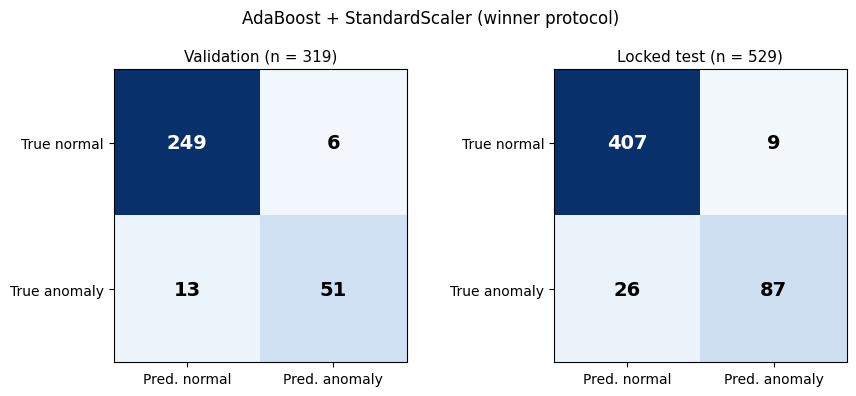

In [111]:
# Figure 1: confusion matrices for the winning protocol (AdaBoost + StandardScaler).
# Descriptive only: the protocol was locked on validation before touching the test set.
def plot_confusion(ax, y_true, y_pred, panel_title):
    """Render one confusion matrix panel (labels: 0=normal, 1=anomaly)."""
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    fontsize=14, fontweight="bold",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], labels=["Pred. normal", "Pred. anomaly"])
    ax.set_yticks([0, 1], labels=["True normal", "True anomaly"])
    ax.set_title(panel_title, fontsize=11)
    ax.set_xlabel("")
    return cm


y_val_pred = winner.predict(X_validation_standard)
y_test_pred = winner.predict(X_test)

# Sanity check: must reproduce the reported metrics (validation MCC .808, test MCC .796).
print("Validation MCC:", round(matthews_corrcoef(y_validation, y_val_pred), 3))
print("Test MCC:", round(matthews_corrcoef(y_test, y_test_pred), 3))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
plot_confusion(axes[0], y_validation, y_val_pred, "Validation (n = 319)")
plot_confusion(axes[1], y_test, y_test_pred, "Locked test (n = 529)")
fig.suptitle("AdaBoost + StandardScaler (winner protocol)", fontsize=12)
fig.tight_layout()
plt.show()

**Figure 1.** Confusion matrices for AdaBoost with StandardScaler on the
validation partition and the locked test partition. Validation results were
used for model selection; the locked test results are shown only as the final
evaluation.

### Validation error analysis

On the 319-segment validation partition, the selected AdaBoost + StandardScaler
model classified 300 segments correctly, with 13 false negatives and 6 false
positives. These errors are summarized by channel and declared sampling
interval in the preceding table.

The error counts vary across channel–sampling groups. For example, the model
produced three false positives among 11 nominal validation segments in
CADC0894 at sampling = 1. In CADC0892 at sampling = 1, it missed two of the
six anomalous segments. These are descriptive observations from the validation
partition, not reliable estimates of performance for each channel: several
groups contain only a small number of observations.

The available analysis identifies where validation errors occurred, but it does
not establish their physical causes. In particular, explanations such as
low-energy signal behavior or label-boundary ambiguity should be treated as
hypotheses unless supported by a separate inspection of the raw telemetry and
the dataset's labeling procedure. No conclusions about operational behavior
should be drawn from this validation-only error analysis.

In [112]:
# Verification: the locked test was standardized with the subtrain-fitted scaler.
assert standard_scaler.n_samples_seen_ == 1018  # rows seen at fit = nominal subtrain only
np.testing.assert_allclose(
    standard_scaler.mean_, normal_subtrain_df[features].mean().to_numpy(), rtol=1e-10
)
np.testing.assert_allclose(
    standard_scaler.var_, normal_subtrain_df[features].var(ddof=0).to_numpy(), rtol=1e-10
)
np.testing.assert_array_equal(X_test, standard_scaler.transform(test_df[features]))
print("OK: X_test uses the StandardScaler fit on the 1,018 nominal subtrain segments; "
      "no refit on validation or test.")

OK: X_test uses the StandardScaler fit on the 1,018 nominal subtrain segments; no refit on validation or test.


In [113]:
# Validation results table.
# This is for model/preprocessing selection only; it does not use the locked test set.

validation_table = (
    results_df[
        [
            "model",
            "preprocessing",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "MCC",
            "AUC_PR",
            "AUC_ROC",
            "PREC_N_SCORES",
        ]
    ]
    .sort_values(
        ["MCC", "AUC_PR"],
        ascending=[False, False],
    )
    .reset_index(drop=True)
)

display(
    validation_table.style
    .format(
        {
            "Accuracy": "{:.3f}",
            "Precision": "{:.3f}",
            "Recall": "{:.3f}",
            "F1": "{:.3f}",
            "MCC": "{:.3f}",
            "AUC_PR": "{:.3f}",
            "AUC_ROC": "{:.3f}",
            "PREC_N_SCORES": "{:.3f}",
        }
    )
    .set_caption(
        "Table 1. Validation performance by model and preprocessing variant. "
        "Rows are sorted by MCC and then AUC-PR. The locked test set was not "
        "used for selection."
    )
)

,model,preprocessing,Accuracy,Precision,Recall,F1,MCC,AUC_PR,AUC_ROC,PREC_N_SCORES
0,AdaBoost,standard,0.940,0.895,0.797,0.843,0.808,0.931,0.967,0.875
1,AdaBoost,raw,0.940,0.895,0.797,0.843,0.808,0.916,0.962,0.850
2,AdaBoost,robust,0.940,0.895,0.797,0.843,0.808,0.916,0.962,0.850
3,IForest,raw,0.746,0.333,0.266,0.296,0.145,0.328,0.683,0.344
4,IForest,robust,0.746,0.333,0.266,0.296,0.145,0.328,0.683,0.344
5,IForest,standard,0.743,0.320,0.250,0.281,0.129,0.349,0.686,0.328


**Validation results.** AdaBoost achieved the strongest validation performance
across the tested preprocessing variants. Under the pre-declared selection
criteria—MCC first and AUC-PR second—AdaBoost with StandardScaler was selected
(MCC = 0.808; AUC-PR = 0.931). Its classification metrics were unchanged across
the three variants, while StandardScaler yielded the best ranking metrics.
Isolation Forest performed substantially worse on this feature set
(validation MCC = 0.129–0.145). These validation results were used for
selection; they are not final test estimates.

In [114]:
# Final locked-test results.
# These calls only report predictions from the already-fitted models.

test_rows = []

for model_name, model in [
    ("AdaBoost + StandardScaler (subtrain fit)", winner),
    ("Original recipe reference (full-train fit)", original_recipe),
]:
    row = {
        "model": model_name,
        **evaluate_metrics(
            y_test,
            model.predict(X_test),
            model.decision_function(X_test),
        ),
    }
    test_rows.append(row)

test_results_df = pd.DataFrame(test_rows)

display(
    test_results_df.style
    .format(
        {
            "Accuracy": "{:.3f}",
            "Precision": "{:.3f}",
            "Recall": "{:.3f}",
            "F1": "{:.3f}",
            "MCC": "{:.3f}",
            "AUC_PR": "{:.3f}",
            "AUC_ROC": "{:.3f}",
            "PREC_N_SCORES": "{:.3f}",
        }
    )
    .set_caption(
        "Table 2. Final evaluation on the locked test set. "
        "The validation-selected model is reported alongside the original-recipe "
        "reference; the reference uses a different training/preprocessing protocol."
    )
)

,model,Accuracy,Precision,Recall,F1,MCC,AUC_PR,AUC_ROC,PREC_N_SCORES
0,AdaBoost + StandardScaler (subtrain fit),0.934,0.906,0.770,0.833,0.796,0.924,0.962,0.850
1,Original recipe reference (full-train fit),0.928,0.887,0.761,0.819,0.778,0.910,0.951,0.832


Note: The reference model was fitted using the full-train scaler but evaluated on the subtrain-scaled test matrix; it is a hybrid reference, not a literal reproduction of the original test-side preprocessing.
**Locked-test results.** The validation-selected AdaBoost + StandardScaler
protocol achieved MCC = 0.796 and AUC-PR = 0.924 on the locked test set. The
original-recipe reference achieved MCC = 0.778 and AUC-PR = 0.910. These values
are descriptive comparisons between different training and preprocessing
protocols; the difference cannot be attributed to a single methodological
change. The test set was not used for model or preprocessing selection.

## Methods

### Data and feature representation

We use OPS-SAT-AD v2 (Zenodo record 15108715), a labeled telemetry anomaly dataset derived from ESA's OPS-SAT spacecraft. The analysis uses the shipped segment-level feature table (`dataset.csv`, 2,123 segments), generated from raw telemetry (`segments.csv`, 303,493 samples) by the dataset generator. This audit independently reproduces three time-related features—`len`, `duration`, and `gaps_squared`—for all 2,123 segments; it does not independently reproduce all 18 features. The binary `anomaly` column is the modeling target; `label` is not used as a target.

### Partitioning

The shipped train/test assignment (1,594 / 529) is preserved. The 529 test segments are held out from model and preprocessing selection. The 1,594 training segments are re-partitioned 80/20 into subtrain (n = 1,275; 1,018 nominal, 257 anomalous) and validation (n = 319; 255 nominal, 64 anomalous), stratified by `anomaly` with fixed seed 2137. Disjointness is asserted using segment IDs.

### Preprocessing variants

Three variants are compared: raw features (control), `StandardScaler`, and `RobustScaler`. Each scaler is fitted only on the 1,018 nominal subtraining segments and applied to subtraining and validation. After model and preprocessing selection is complete, the selected StandardScaler is applied to the locked test data without refitting. This differs from the original notebook's scaler fit on all normal training segments, which includes the validation subset in this audit's split.

### Models and evaluation

AdaBoost is fitted on all 1,275 subtraining rows with labels. Isolation Forest is fitted on the 1,018 nominal subtraining rows; labels are used only for evaluation. The random seed is 2137.

Preprocessing/model configurations are compared on validation using MCC first and AUC-PR second. After selection on validation, the winning configuration is evaluated once on the locked test set. A separate full-training reference run is reported for descriptive comparison; it uses the full-train scaler for training but the subtrain-fitted scaler for test features, so it is a hybrid reference rather than a literal reproduction. Neither test result is used for model or preprocessing selection.

Reported metrics are Accuracy, Precision, Recall, F1, MCC, AUC-PR, AUC-ROC, and precision@n. Scaler provenance is checked by assertions.

## Limitations

1. **Single split and no uncertainty quantification.** Comparisons use one stratified training/validation split and one locked-test evaluation. Small metric differences are reported descriptively, not as statistically significant effects.
2. **No independent raw-signal analysis.** The audit does not establish whether the feature representation misses any physical anomaly type.
3. **Label and segmentation policy not assessed.** The available files do not establish the labeling procedure or possible boundary ambiguity; this is not used to explain errors.
4. **Sampling irregularity and short segments.** 1,318 intervals across 151 segments differ from the declared sampling value. Their causes cannot be verified from the files. Some segments contain very few samples, which may make smoothed peak features sensitive to edge handling.
5. **Limited model scope.** Both detectors use default hyperparameters and one configuration each. Channel semantics are not established, so results are not given a physical channel-level interpretation.


## Conclusion

This audit found that, among the evaluated models and preprocessing variants,
AdaBoost with StandardScaler provided the strongest validation performance
under the pre-declared MCC-first, AUC-PR-second selection rule. Its final
evaluation on the locked test set yielded MCC = 0.796 and AUC-PR = 0.924.
Isolation Forest performed substantially worse on the same segment-level
feature representation.

The preprocessing comparison showed that scaling did not change AdaBoost's
validation classification metrics, although StandardScaler produced the best
validation ranking metrics. The result therefore supports a specific
comparison on the supplied OPS-SAT-AD v2 features and split; it does not show
that scaling will have the same effect on other datasets or operational
telemetry.

The project also identified data-quality considerations relevant to future
work, including irregular intervals in some segments and limitations in the
available documentation of channel semantics and segmentation. These findings
motivate further study of temporal feature construction, raw-signal behavior,
and sensitivity to gaps. The current analysis is a reproducible dataset audit
and model comparison, not a validated onboard or flight-ready system.

## Reproducibility

Place `segments.csv`, `dataset.csv`, and this notebook in the same working directory. Run all cells from top to bottom in a fresh environment. The workflow uses pandas, NumPy, scikit-learn, PyOD, and Matplotlib; the notebook records installed versions and uses seed 2137.

Before sharing, restart the runtime and run all cells in order. Confirm that there are no errors and that the generated validation and locked-test tables match the outputs from that clean run. The locked test must not be used for additional model or preprocessing selection.

## References

Bogdan, R. (2024). *OPSSAT-AD - anomaly detection dataset for satellite telemetry* [Dataset]. Ruszczak. https://doi.org/10.5281/zenodo.15108715
